In [1]:
pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 81.2 MB/s eta 0:00:00
  Attempting uninstall: nvidia-nvjitlink-cu12
    Found existing installation: nvidia-nvjitlink-cu12 12.8.93
    Uninstalling nvidia-nvjitlink-cu12-12.8.93:
      Successfully uninstalled nvidia-nvjitlink-cu12-12.8.93
  Attempting uninstall: nvidia-curand-cu12
    Found existing installation: nvidia-curand-cu12 10.3.9.90
    Uninstalling nvidia-curand-cu12-10.3.9.

In [2]:
import os
from glob import glob
from tqdm.notebook import tqdm
from ultralytics import YOLO
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import pandas as pd
import random
import torch
import shutil
from pathlib import Path
from tqdm.auto import tqdm
import yaml

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
!cp -r /kaggle/input/rasoul-multiclass-aabb/dataset /kaggle/working/

In [4]:
# --- 0. MULTICLASS CONFIGURATION ---
CLASS_ID_TO_NAME = {0: 'ICH', 1: 'IVH', 2: 'EPH', 3: 'SDH', 4: 'SAH'}
CLASS_NAMES = list(CLASS_ID_TO_NAME.values())

In [5]:
# Set the seed value
SEED = 42  

# Python’s built-in random module
random.seed(SEED)

# NumPy
np.random.seed(SEED)

# PyTorch
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Ensure deterministic behavior in PyTorch
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Set PYTHONHASHSEED to ensure consistent behavior in hash-based operations
os.environ["PYTHONHASHSEED"] = str(SEED)

In [6]:
models = [
    "yolov8n", "yolov8s", "yolov8m",
    "yolo11n", "yolo11s", "yolo11m",
    "yolo12n", "yolo12s", "yolo12m"
]

In [7]:
# --- 1. SETUP AND PATH DEFINITIONS ---
dataset_yaml_path = Path("/kaggle/working/dataset.yaml")
weights_dir = Path('/kaggle/input/yolo-multiclass-detection-weights/MulticlassDetectionWeights')
threshold_csv_path = '/kaggle/input/c-threshold-for-r-m-aabb-w/data_outputs/model_performance_summary.csv'
output_dir_data = Path("/kaggle/working/data_outputs")
output_dir_plots = Path("/kaggle/working/myplots")
output_dir_final_runs = Path("/kaggle/working/optimal_runs")
output_dir_classwise_plots = output_dir_plots / "classwise"

# Create all necessary output directories
os.makedirs(output_dir_data, exist_ok=True)
os.makedirs(output_dir_plots, exist_ok=True)
os.makedirs(output_dir_final_runs, exist_ok=True)
os.makedirs(output_dir_plots / "ConfMats", exist_ok=True)
os.makedirs(output_dir_classwise_plots, exist_ok=True) ### NEW: Directory for class-wise plots

In [8]:
# --- Generating yaml file for multiclass ---
### MODIFIED: The YAML now uses the CLASS_NAMES list for multiclass setup.
data = {
    'train': '/kaggle/working/dataset/images/train',
    'val': '/kaggle/working/dataset/images/val',
    'test': '/kaggle/working/dataset/images/test',
    'nc': len(CLASS_NAMES),
    'names': CLASS_NAMES
}

# Save YAML file
with open(dataset_yaml_path, 'w') as file:
    yaml.dump(data, file, default_flow_style=False)
print(f"✅ YAML file for {len(CLASS_NAMES)} classes saved at: {dataset_yaml_path}")

✅ YAML file for 5 classes saved at: /kaggle/working/dataset.yaml


In [9]:
def organize_confusion_matrices(source_dir: Path, dest_dir: Path):
    """
    Finds confusion matrices in subdirectories, renames them, and copies them.
    """
    dest_dir.mkdir(parents=True, exist_ok=True)
    source_files = list(source_dir.glob('*/confusion_matrix.png'))
    if not source_files:
        print(f"⚠️ Warning: No 'confusion_matrix.png' files found under '{source_dir}'")
        return
    print(f"Found {len(source_files)} confusion matrices. Copying to '{dest_dir}'...")
    for source_path in tqdm(source_files, desc="Copying Matrices"):
        try:
            model_name = source_path.parent.name
            dest_path = dest_dir / f"{model_name}_confusion_matrix.png"
            shutil.copy(source_path, dest_path)
        except Exception as e:
            print(f"❌ Error processing {source_path.name}: {e}")
    print(f"\n✅ Copying complete.")

In [10]:
# Load the optimal thresholds from the tuning script
try:
    threshold_df = pd.read_csv(threshold_csv_path)
    threshold_map = dict(zip(threshold_df['model'], threshold_df['best_threshold']))
except FileNotFoundError:
    print(f"Error: Threshold CSV not found at {threshold_csv_path}. Script will stop.")
    exit()

In [11]:
# --- 2. FINAL INFERENCE AND EVALUATION LOOP ---
output_results_classwise = [] ### MODIFIED: Renamed to clarify it holds class-wise data
model_paths = list(weights_dir.glob('*.pt'))
pbar = tqdm(model_paths, desc="Processing models")

for model_path in pbar:
    model_name = model_path.stem
    pbar.set_description(f"Processing {model_name}")

    conf_threshold = threshold_map[model_name]
    model = YOLO(model_path)

    metrics = model.val(
        data=str(dataset_yaml_path),
        split='test',
        conf=conf_threshold,
        iou=0.5,
        save_txt=True,
        save_conf=True,
        plots=True,
        project='/kaggle/working/inference_runs',
        name=model_name,
        exist_ok=True,
        verbose=False,
        seed=SEED,
        device=0
    )

    ### MODIFIED: Collect metrics for each class individually
    # metrics.box.p, .r, and .f1 are arrays where each index corresponds to a class
    per_class_precision = metrics.box.p
    per_class_recall = metrics.box.r
    per_class_f1 = metrics.box.f1

    for i, class_name in enumerate(CLASS_NAMES):
        output_results_classwise.append({
            'model': model_name,
            'class': class_name,
            'threshold': conf_threshold,
            'precision': per_class_precision[i],
            'recall': per_class_recall[i],
            'f1': per_class_f1[i],
            'mAP@0.5': metrics.box.map50, # Overall mAP is the same for all classes
            'mAP@0.5:0.95': metrics.box.map
        })

pbar.close()

Processing models:   0%|          | 0/9 [00:00<?, ?it/s]

Ultralytics 8.3.203 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 92 layers, 25,842,655 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 835.0±527.7 MB/s, size: 32.9 KB)
val: Scanning /kaggle/working/dataset/labels/test... 2429 images, 1906 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2429/2429 1.5Kit/s 1.6s
val: New cache created: /kaggle/working/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 152/152 2.8it/s 53.6s


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       2429        815      0.344      0.283      0.287      0.193
Speed: 0.3ms preprocess, 19.8ms inference, 0.0ms loss, 0.3ms postprocess per image
Results saved to /kaggle/working/inference_runs/yolov8m
Ultralytics 8.3.203 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv12n summary (fused): 159 layers, 2,557,703 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 999.4±817.3 MB/s, size: 35.6 KB)
val: Scanning /kaggle/working/dataset/labels/test.cache... 2429 images, 1906 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2429/2429 4.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 152/152 8.6it/s 17.7s


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


...

                   all       2429        815      0.327      0.283      0.263      0.175
Speed: 0.3ms preprocess, 9.3ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /kaggle/working/inference_runs/yolov8s
Ultralytics 8.3.203 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv12s summary (fused): 159 layers, 9,232,815 parameters, 0 gradients, 21.2 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 898.4±718.7 MB/s, size: 32.6 KB)
val: Scanning /kaggle/working/dataset/labels/test.cache... 2429 images, 1906 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2429/2429 4.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 152/152 4.1it/s 37.3s


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       2429        815      0.467      0.244      0.349      0.227
Speed: 0.4ms preprocess, 13.9ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /kaggle/working/inference_runs/yolo12s
Ultralytics 8.3.203 🚀 Python-3.11.11 torch-2.5.1+cu124 CUDA:0 (Tesla T4, 15095MiB)
Model summary (fused): 72 layers, 3,006,623 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1190.5±376.5 MB/s, size: 38.3 KB)
val: Scanning /kaggle/working/dataset/labels/test.cache... 2429 images, 1906 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2429/2429 3.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 152/152 11.5it/s 13.2s


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1
/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  xa[xa < 0] = -1


                   all       2429        815      0.436      0.223      0.319      0.216
Speed: 0.4ms preprocess, 3.8ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to /kaggle/working/inference_runs/yolov8n



--- Class-wise Test Set Performance ---
     model class  threshold  precision    recall        f1   mAP@0.5  \
0  yolov8m   ICH        0.3   0.779292  0.674528  0.723135  0.287131   
1  yolov8m   IVH        0.3   0.294118  0.212766  0.246914  0.287131   
2  yolov8m   EPH        0.3   0.384615  0.227273  0.285714  0.287131   
3  yolov8m   SDH        0.3   0.196532  0.191011  0.193732  0.287131   
4  yolov8m   SAH        0.3   0.063830  0.107143  0.080000  0.287131   

   mAP@0.5:0.95  
0      0.192861  
1      0.192861  
2      0.192861  
3      0.192861  
4      0.192861  

--- Overall (Mean) Test Set Performance ---
     model  threshold        f1  precision    recall   mAP@0.5  mAP@0.5:0.95
0  yolo11m       0.75  0.226036   0.377444  0.178225  0.268092      0.178862
1  yolo11n       0.30  0.249605   0.311579  0.220945  0.273908      0.194357
2  yolo11s       0.80  0.216169   0.446923  0.162536  0.304330      0.197253
3  yolo12m       0.40  0.302682   0.353696  0.272706  0.303673   

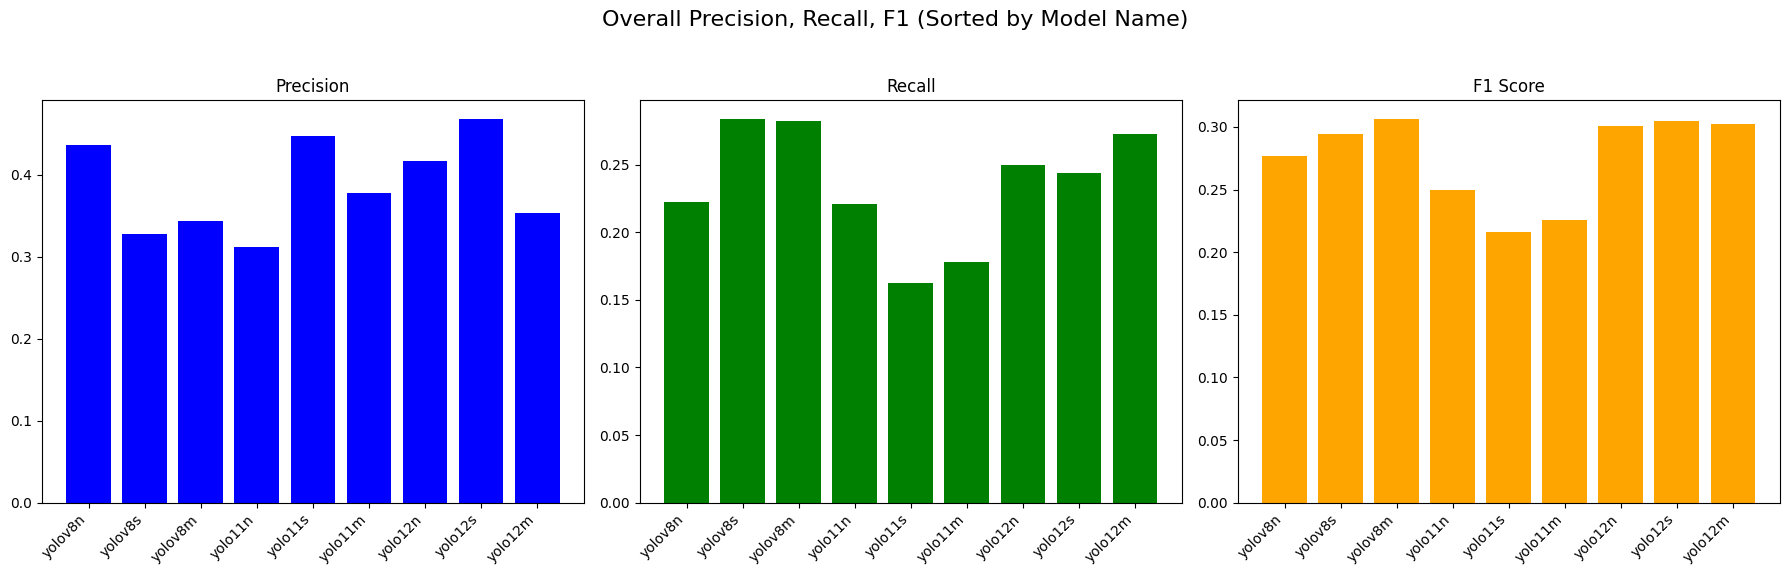

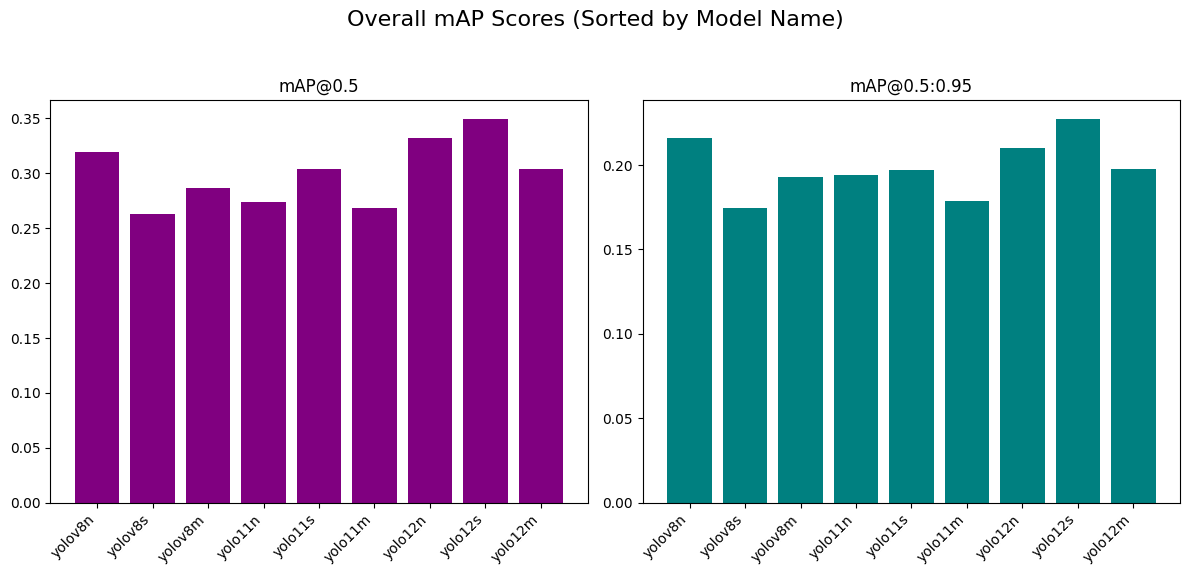


--- Generating plots for overall (mean) performance sorted by value ---


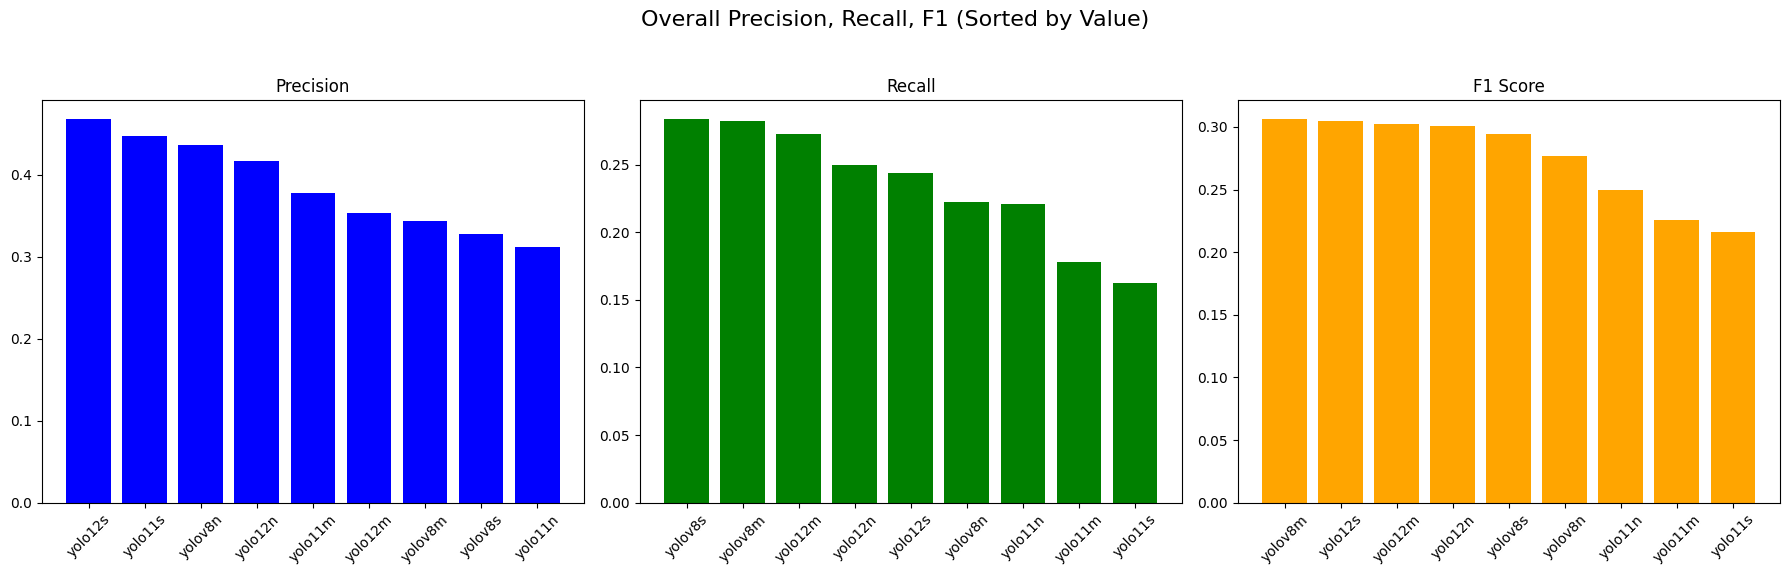

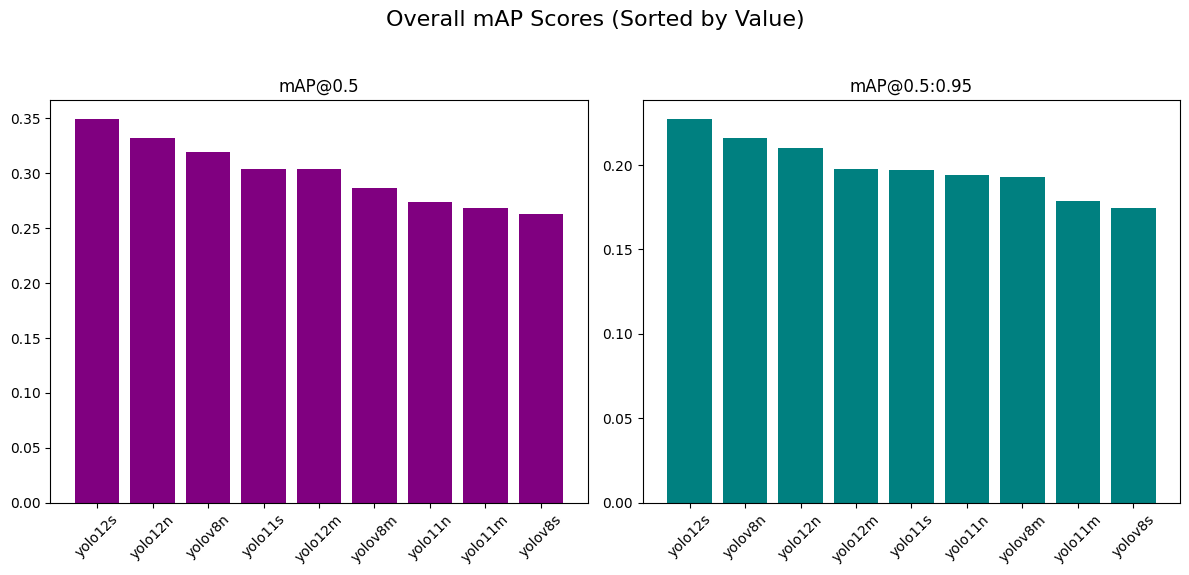

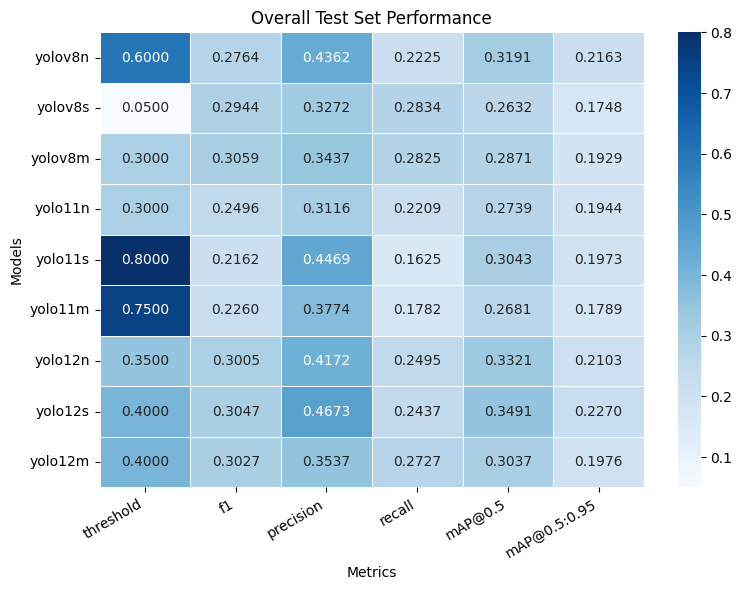


--- Generating plots for each class ---


Generating Class Plots:   0%|          | 0/5 [00:00<?, ?it/s]

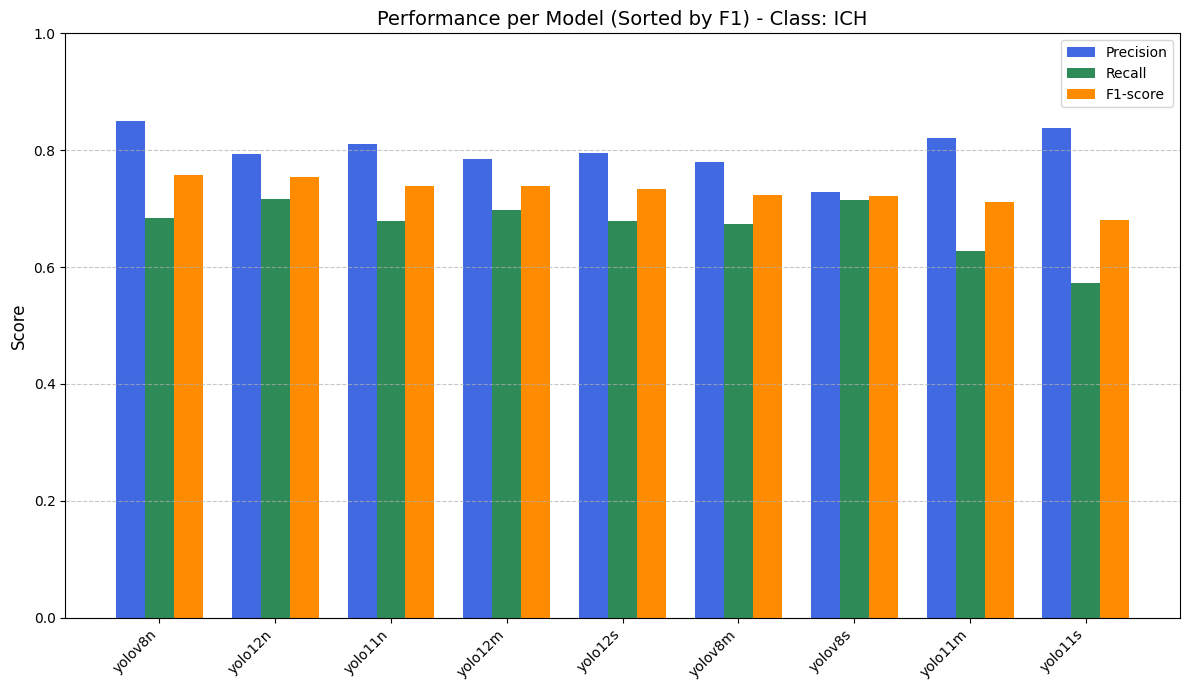

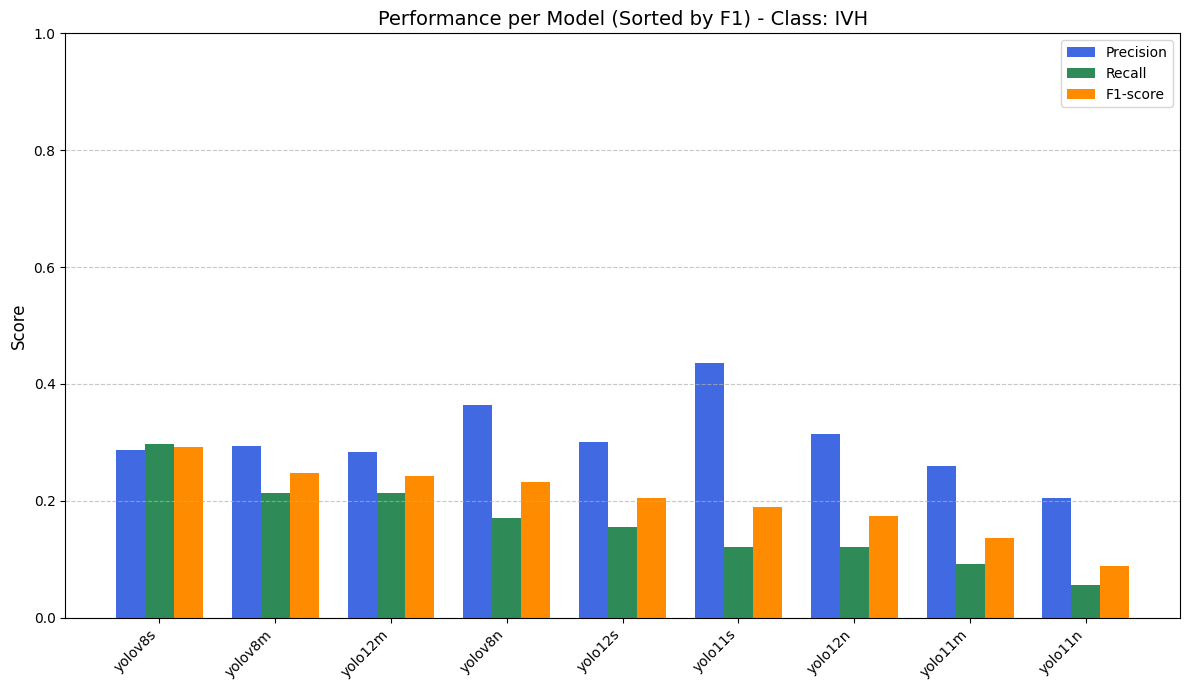

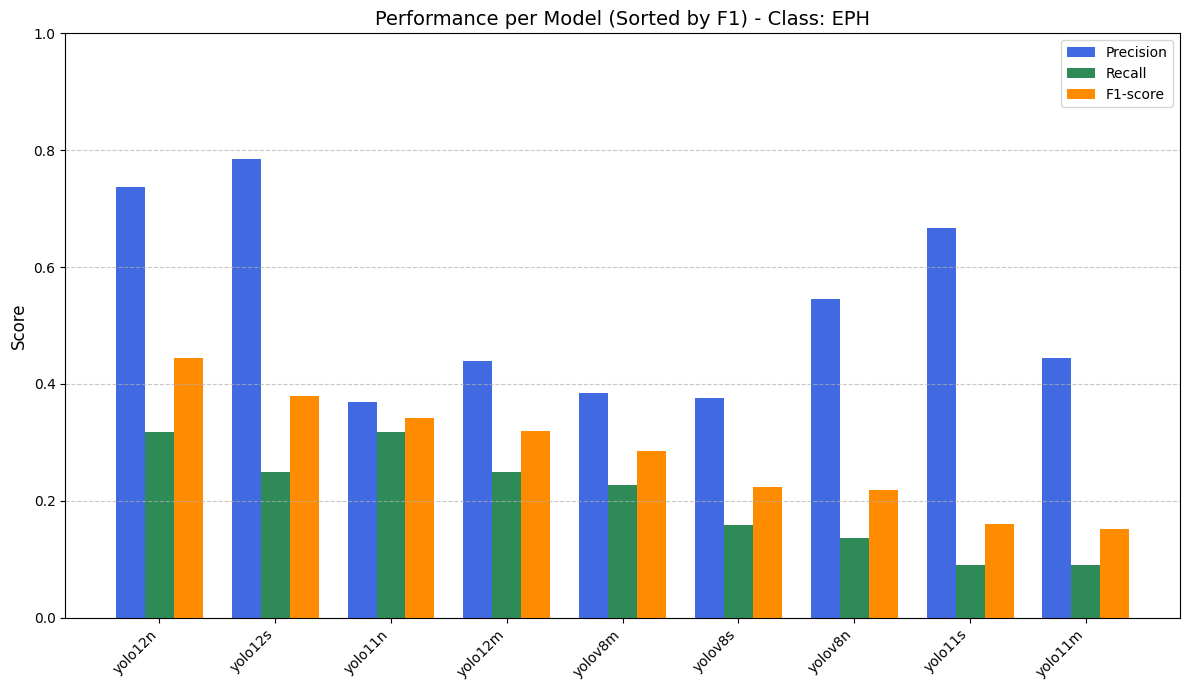

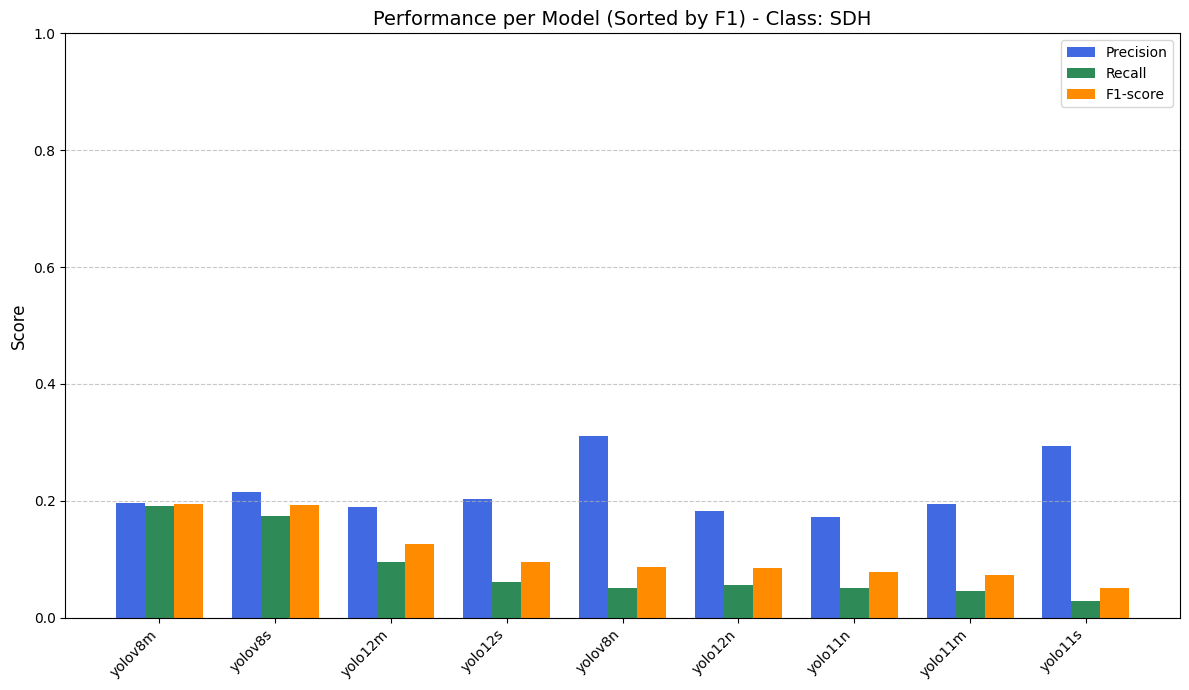

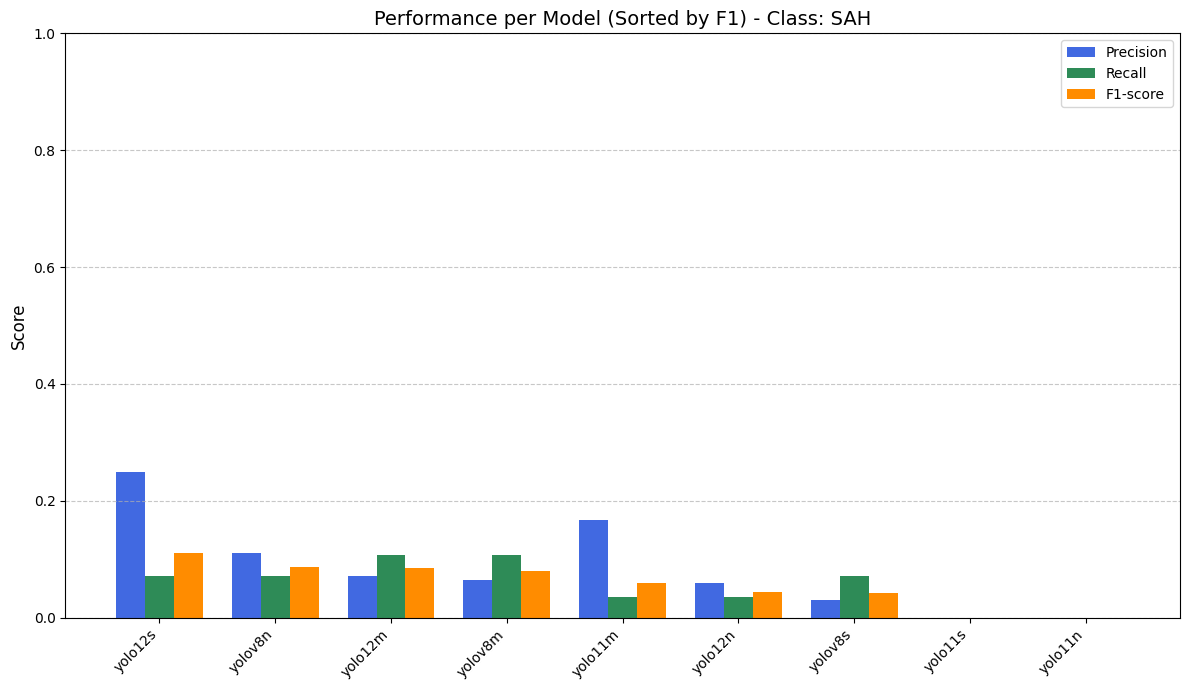


--- Organizing final confusion matrices ---
Found 9 confusion matrices. Copying to '/kaggle/working/myplots/ConfMats'...


Copying Matrices:   0%|          | 0/9 [00:00<?, ?it/s]


✅ Copying complete.

✅ All tasks complete.


In [12]:
# --- 3. MODIFIED REPORTING AND PLOTTING SECTION ---
if not output_results_classwise:
    print("No results were generated. Exiting.")
else:
    # --- Create DataFrames ---
    df_classwise = pd.DataFrame(output_results_classwise)
    df_classwise.to_csv(output_dir_data / 'output_results_classwise_metrics.csv', index=False)
    print("\n--- Class-wise Test Set Performance ---")
    print(df_classwise.head())

    df_overall = df_classwise.groupby('model').agg({
        'precision': 'mean',
        'recall': 'mean',
        'f1': 'mean',
        'mAP@0.5': 'first',
        'mAP@0.5:0.95': 'first',
        'threshold': 'first'
    }).reset_index()

    # ADD THIS: Explicitly set the column order to match the binary script
    column_order = ['model', 'threshold', 'f1', 'precision', 'recall', 'mAP@0.5', 'mAP@0.5:0.95']
    df_overall = df_overall[column_order]

    df_overall.to_csv(output_dir_data / 'output_results_overall_metrics.csv', index=False)
    print("\n--- Overall (Mean) Test Set Performance ---")
    print(df_overall)

    # --- Setup for Plotting ---
    models_order = ["yolov8n", "yolov8s", "yolov8m",
                    "yolo11n", "yolo11s", "yolo11m",
                    "yolo12n", "yolo12s", "yolo12m"]
    df_overall['model'] = pd.Categorical(df_overall['model'], categories=models_order, ordered=True)
    df_ordered_overall = df_overall.sort_values('model')

    # --- PLOTS FOR OVERALL (MEAN) PERFORMANCE (SORTED BY NAME) ---
    print("\n--- Generating plots for overall (mean) performance sorted by name ---")
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle('Overall Precision, Recall, F1 (Sorted by Model Name)', fontsize=16)
    x = np.arange(len(df_ordered_overall))
    
    axes[0].bar(x, df_ordered_overall['precision'], color='blue')
    axes[0].set_title('Precision')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(df_ordered_overall['model'], rotation=45, ha='right')

    axes[1].bar(x, df_ordered_overall['recall'], color='green')
    axes[1].set_title('Recall')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(df_ordered_overall['model'], rotation=45, ha='right')

    axes[2].bar(x, df_ordered_overall['f1'], color='orange')
    axes[2].set_title('F1 Score')
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(df_ordered_overall['model'], rotation=45, ha='right')
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(output_dir_plots / "Overall_PRF_byName.png")
    plt.show()

    # ADDED: mAP plots sorted by model name
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    fig.suptitle('Overall mAP Scores (Sorted by Model Name)', fontsize=16)

    axes[0].bar(x, df_ordered_overall['mAP@0.5'], color='purple')
    axes[0].set_title('mAP@0.5')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(df_ordered_overall['model'], rotation=45, ha='right')

    axes[1].bar(x, df_ordered_overall['mAP@0.5:0.95'], color='teal')
    axes[1].set_title('mAP@0.5:0.95')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(df_ordered_overall['model'], rotation=45, ha='right')

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(output_dir_plots / "Overall_mAP_byName.png")
    plt.show()

    # --- ADDED: PLOTS FOR OVERALL (MEAN) PERFORMANCE (SORTED BY VALUE) ---
    print("\n--- Generating plots for overall (mean) performance sorted by value ---")
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle('Overall Precision, Recall, F1 (Sorted by Value)', fontsize=16)

    df_p = df_ordered_overall.sort_values(by='precision', ascending=False)
    axes[0].bar(df_p['model'], df_p['precision'], color='blue')
    axes[0].set_title('Precision')
    axes[0].tick_params(axis='x', rotation=45)

    df_r = df_ordered_overall.sort_values(by='recall', ascending=False)
    axes[1].bar(df_r['model'], df_r['recall'], color='green')
    axes[1].set_title('Recall')
    axes[1].tick_params(axis='x', rotation=45)

    df_f = df_ordered_overall.sort_values(by='f1', ascending=False)
    axes[2].bar(df_f['model'], df_f['f1'], color='orange')
    axes[2].set_title('F1 Score')
    axes[2].tick_params(axis='x', rotation=45)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(output_dir_plots / "Overall_PRF_byValue.png")
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(12, 6))
    fig.suptitle('Overall mAP Scores (Sorted by Value)', fontsize=16)

    df_m50 = df_ordered_overall.sort_values(by='mAP@0.5', ascending=False)
    axes[0].bar(df_m50['model'], df_m50['mAP@0.5'], color='purple')
    axes[0].set_title('mAP@0.5')
    axes[0].tick_params(axis='x', rotation=45)

    df_m95 = df_ordered_overall.sort_values(by='mAP@0.5:0.95', ascending=False)
    axes[1].bar(df_m95['model'], df_m95['mAP@0.5:0.95'], color='teal')
    axes[1].set_title('mAP@0.5:0.95')
    axes[1].tick_params(axis='x', rotation=45)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.savefig(output_dir_plots / "Overall_mAP_byValue.png")
    plt.show()

    # --- MODIFIED: Heatmap of overall performance ---
    df_heatmap = df_ordered_overall.set_index('model')
    plt.figure(figsize=(8, 6))
    sns.heatmap(df_heatmap, annot=True, fmt=".4f", cmap="Blues", linewidths=.5, cbar=True)
    plt.title("Overall Test Set Performance")
    plt.xlabel("Metrics")
    plt.ylabel("Models")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.savefig(output_dir_plots / "Overall_Metrics_Heatmap.png")
    plt.show()

    # --- CLASS-WISE PLOTTING (Unchanged) ---
    print("\n--- Generating plots for each class ---")
    df_classwise['model'] = pd.Categorical(df_classwise['model'], categories=models_order, ordered=True)

    for cls_name in tqdm(CLASS_NAMES, desc="Generating Class Plots"):
        cls_df = df_classwise[df_classwise['class'] == cls_name].copy()
        cls_df = cls_df.sort_values('f1', ascending=False)

        fig, ax = plt.subplots(figsize=(12, 7))
        x = np.arange(len(cls_df))
        width = 0.25

        ax.bar(x - width, cls_df['precision'], width, label='Precision', color='royalblue')
        ax.bar(x, cls_df['recall'], width, label='Recall', color='seagreen')
        ax.bar(x + width, cls_df['f1'], width, label='F1-score', color='darkorange')

        ax.set_ylabel('Score', fontsize=12)
        ax.set_title(f"Performance per Model (Sorted by F1) - Class: {cls_name}", fontsize=14)
        ax.set_xticks(x)
        ax.set_xticklabels(cls_df['model'], rotation=45, ha='right')
        ax.set_ylim(0, 1)
        ax.legend()
        ax.grid(axis='y', linestyle='--', alpha=0.7)

        plt.tight_layout()
        plt.savefig(output_dir_classwise_plots / f"{cls_name}_Performance_F1-sorted.png", dpi=300)
        plt.show()

    # --- Organize Confusion Matrices ---
    print("\n--- Organizing final confusion matrices ---")
    source_directory_for_cms = Path("/kaggle/working/inference_runs")
    destination_directory_for_cms = output_dir_plots / "ConfMats"
    organize_confusion_matrices(source_directory_for_cms, destination_directory_for_cms)

    print("\n✅ All tasks complete.")

In [13]:
!rm -rf /kaggle/working/dataset